In [1]:
!pip install lmfit


[notice] A new release of pip is available: 26.0.1 -> 26.3
[notice] To update, run: pip install --upgrade pip


In [2]:
import matplotlib.pyplot as plt
import os
import scipy
from scipy.optimize import curve_fit
import numpy as np
import csv
from scipy.stats import linregress

from lmfit import Minimizer, Parameters, report_fit
import asteval
import uncertainties

In [3]:
file = "Calib.txt"
yellow_basic = "./Measurment Data/Yellow Lines/579nm2s100F Calibration.dat"
yellow_full = "./Measurment Data/Yellow Lines/579nm2s100F Without Pol 28A.dat"
yellow_pol90 = "./Measurment Data/Yellow Lines/579nm2s100F With Pol 90° 28A.dat"
yellow_pol180 = "./Measurment Data/Yellow Lines/579nm2s100F With Pol 180° 28A.dat"
DarkFrame1 = "./Measurment Data/Dark Frames/2s1000F.dat"
DarkFrame2 = "./Measurment Data/Dark Frames/282ms500F.dat"
green_basic = "./Measurment Data/Green Line/Calibration.dat"
green_full = "./Measurment Data/Green Line/Without Pol 27A.dat"
green_pol90 = "./Measurment Data/Green Line/With Pol 90° 27A.dat"
green_pol180 = "./Measurment Data/Green Line/With Pol 180° 27A.dat"

In [4]:
def read_mag_calib(filename):
    
    current = []
    fieldstrength = []
    
    with open(filename, newline="") as f:
        reader = csv.reader(f)
        next(reader) #skips header
        for row in reader:
            data = row[0].split("\t")
            current.append(int(data[0]))
            fieldstrength.append(int(data[1]))
    return current, fieldstrength

def get_mag_strength(current):
    current_calib, fieldstrength = read_mag_calib(file)
    for i in current_calib:
        if current_calib[i] == current:
            return fieldstrength[i]
        
def read_image(filepath):
    image = []
    with open(filepath, newline="") as f:
        reader = csv.reader(f)
        for row in reader:
            pixelrow = np.array(row[0].split("\t"))
            image.append(pixelrow.astype(int))
        return np.array(image)
    
def image_line(image, pixelstart, width):
    line = []
    for i in range(len(image)):
        line.append(image[i][pixelstart:pixelstart+width].sum())
    return np.array(line)

def lorentzian(x, amplitude, center, gamma):
    return amplitude * gamma**2 / ((x - center)**2 + gamma**2)

def fit_lorentizian(x_bounds, lineOut): #x_bounds im doppeltem array: [[start,ende],[start,ende]]
    x = np.linspace(0,len(lineOut),len(lineOut))
    
    fit_params_popt = []
    fit_params_pcov = []
    
    for param in x_bounds:
        #https://plotivy.app/techniques/lorentzian-fitting
        bounds = ([0, x.min(), 0.1], [np.inf, x.max(), np.inf])
        popt, pcov = curve_fit(lorentzian, x[param[0]:param[1]], lineOut[param[0]:param[1]], p0=[lineOut.max(), x[np.argmax(lineOut)], 5.0], bounds=bounds)
        
        fit_params_popt.append(popt)
        fit_params_pcov.append(pcov)
        
    return fit_params_popt, fit_params_pcov

def get_lorentzian(lineOut, fits_popt):
    x = np.linspace(0,len(lineOut),len(lineOut))
    
    lorentzians = []
    
    for popt in fits_popt:
        y_fit = lorentzian(x, *popt)
        lorentzians.append(y_fit)
        
    return lorentzians

def lorentzian_res(params, x, data = None, eps_data = None):
    """lmfit: calculates residuals for fitting of a lorentzian function"""
    back = params['back']
    amp = params['amp']
    gamma = params['gamma']
    x0 = params['x0']

    model = back + amp * gamma**2/ ((x - x0)**2 + gamma**2) 

    if data is None:                    # this way you can use the function also to plot the model function itself
        return model
    if eps_data is None:                # to make sure that the function can be used with or w/o uncertainties...
        return (data-model)
    return (data-model) / eps_data

def FP_lorentzian(params, x, data = None, eps_data = None):
    """lmfit: calculates residuals for fitting of 6 lorentzian peaks"""
    
    back = params['back']
    model = back
    
    for i in range(1,int((len(params)-1)/3)+1):
        a = "amp" + str(i)
        g = "gamma" + str(i)
        x0 = "x0" + str(i)
        model += params[a] * params[g]**2/ ((x - params[x0])**2 + params[g]**2)
    
    if data is None:                    # this way you can use the function also to plot the model function itself
        return model
    if eps_data is None:                # to make sure that the function can be used with or w/o uncertainties...
        return (data-model)
    return (data-model) / eps_data

def LM_Lorentzian(params,x):
    back = params['back']
    
    fits = []
    
    for i in range(1,int((len(params)-1)/3)+1):
        a = "amp" + str(i)
        g = "gamma" + str(i)
        x0 = "x0" + str(i)
        y_fit = lorentzian(x, params[a], params[x0], params[g])
        fits.append(y_fit)
    fits = np.array(fits)
    fits += back / len(fits)
    return fits

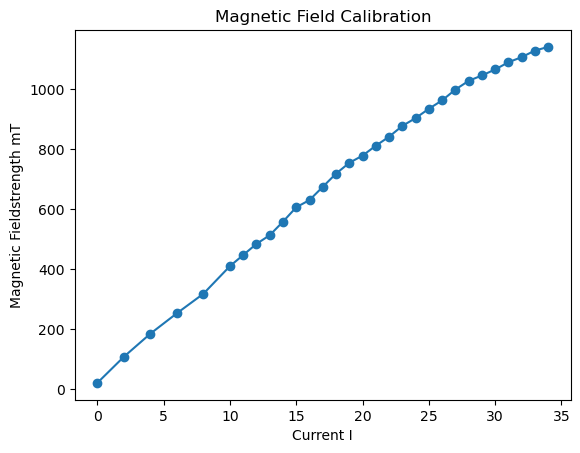

In [5]:
current, fieldstrength = read_mag_calib(file)

plt.plot(current, fieldstrength)  
plt.scatter(current, fieldstrength)  
plt.title("Magnetic Field Calibration")
plt.xlabel("Current I")
plt.ylabel("Magnetic Fieldstrength mT")
plt.show()

In [6]:
DarkFrame_yellow = read_image(DarkFrame1)

yellow_basic_image = read_image(yellow_basic) - DarkFrame_yellow/10
yellow_basic_image[yellow_basic_image < 100] = 0
yellow_basic_image = yellow_basic_image / yellow_basic_image.max()

yellow_full_image = read_image(yellow_full) - DarkFrame_yellow/10
yellow_full_image[yellow_full_image < 100] = 0
yellow_full_image = yellow_full_image / yellow_full_image.max()

yellow_pol90_image = read_image(yellow_pol90) - DarkFrame_yellow/10
yellow_pol90_image[yellow_pol90_image < 100] = 0
yellow_pol90_image = yellow_pol90_image / yellow_pol90_image.max()

yellow_pol180_image = read_image(yellow_pol180) - DarkFrame_yellow/10
yellow_pol180_image[yellow_pol180_image < 100] = 0
yellow_pol180_image = yellow_pol180_image / yellow_pol180_image.max()


#plt.imshow(yellow_basic_image)
##plt.savefig('yellow_basic_image.png')
#plt.show()
#
#plt.imshow(yellow_full_image)
##plt.savefig('yellow_full_image.png')
#plt.show()
#
#plt.imshow(yellow_pol90_image)
##plt.savefig('yellow_pol90_image.png')
#plt.show()
#
#plt.imshow(yellow_pol180_image)
##plt.savefig('yellow_pol180_image.png')
#plt.show()


f= 72.43061195720574 mm
Delta_f= 0.0040353080844093584 mm


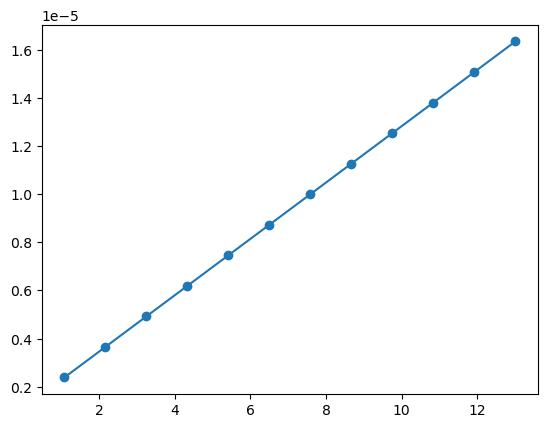

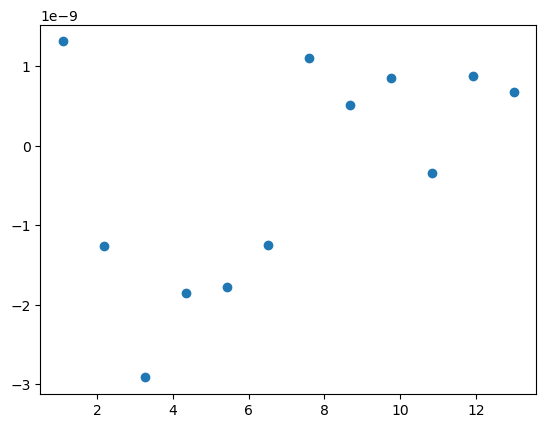

In [7]:
ImageData = read_image(green_basic) - read_image(DarkFrame2)
lineOut = image_line(ImageData, 500, 15)
lineOut_normal = lineOut / max(lineOut)

bounds = [[790,845],[660,718],[590,640],[500,550],[440,480],[370,420],[310,350],[260,300],[210,250],[170,190],[110,140],[70,100],[20,50]]

fit_popt, fit_pcov = fit_lorentizian(bounds, lineOut_normal)
fits = get_lorentzian(lineOut_normal, fit_popt)

#plt.imshow(ImageData)
##plt.savefig('Image-DarkFrame.png')
#plt.show()


view = [1000,1200]
view = [0,len(lineOut)]

#plt.scatter(np.linspace(0,len(lineOut),len(lineOut))[view[0]:view[1]],lineOut_normal[view[0]:view[1]])
#for y_fit in fits:
#    plt.plot(np.linspace(0,len(lineOut),len(lineOut))[view[0]:view[1]],y_fit[view[0]:view[1]],color='red')
#plt.show()

radii = []

for i in range(len(fit_popt)):
    radii.append(fit_popt[i][1])
radii = np.array(radii)
radii -= 1119.4087745576242   #offset to center
radii *= 3.75e-6    #convert pixel to distance
radii *= -1 # kein physikalischer hintergrund nur damit es nicht negativ ist
radii = radii **2

index = 1

wavelength = 546.0735e-9 
d = 2.442e-3 

x = np.linspace(0,len(radii),len(radii))
fit = linregress(x[index:], radii[index:])

pars, cov = np.polyfit(x=x, y=radii, deg=1, w=None, cov=True)
focus= np.sqrt(pars[0]*d/wavelength) 
y_fit = pars[0] * x + pars[1]

residuals = radii - y_fit

focal = np.sqrt((pars[0]*d) / wavelength)

print("f=",focal*1000,"mm")
print("Delta_f=",focal*np.sqrt(np.diag(cov)[0])/pars[0]*0.5*1000, "mm")   # uncertainty propagation from slope to focus

plt.scatter(x[index:],radii[index:])
plt.plot(x[index:],y_fit[index:])
plt.show()

plt.scatter(x[index:],residuals[index:])
plt.show()


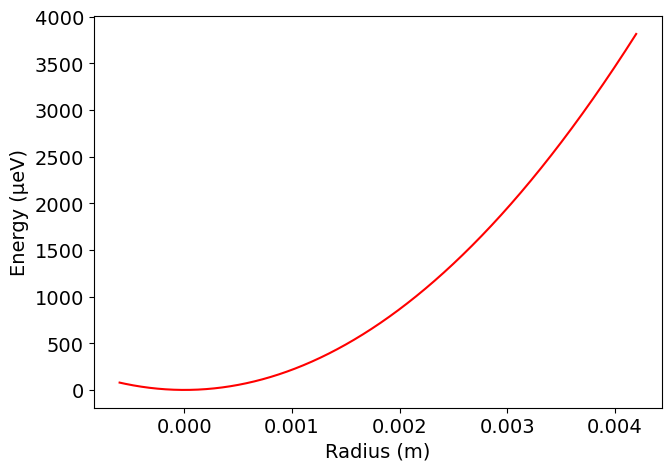

In [8]:
mubohr= 9.2740e-24       # Bohr magneton
hbar= 1.05457e-34      
ee=   1.60218e-19        # elementary charge
cc= 299792458            # speed of light

lambda2eV= cc*hbar/ee*np.pi*2   #conversion between wavelength (in meter) and energy (in eV):  Energy= lambda2eV / lambda

x = np.linspace(0,len(lineOut),len(lineOut))
centerpixel = 1119.4087745576242
radius_0A_lin = -(x  - centerpixel) * 3.75e-6
energyaxis = radius_0A_lin**2*lambda2eV/(2*wavelength*focal**2)*1e6

plt.rcParams.update({'font.size': 16})              # changes font size for plots
plt.rc('xtick', labelsize=14)   
plt.rc('ytick', labelsize=14)   
plt.figure(figsize=(7,5))
plt.ylabel('Energy (µeV)', fontsize=14)
plt.xlabel('Radius (m)', fontsize=14)

plt.plot(radius_0A_lin,energyaxis,'r', markersize=3,label='I=0A') 
plt.tight_layout()

In [9]:
ImageData = read_image(green_basic) - read_image(DarkFrame2)
DarkOut = image_line(read_image(DarkFrame2), 500, 15)
lineOut = image_line(ImageData, 500, 15)
lineOut_normal = lineOut / max(lineOut)
Background = np.average(DarkOut)  
x = np.linspace(0,len(lineOut),len(lineOut))


plt.imshow(green_basic_image)
plt.savefig('green_basic_image.png')
plt.show()

plt.imshow(green_full_image)
plt.savefig('green_full_image.png')
plt.show()

plt.imshow(green_pol90_image)
plt.savefig('green_pol90_image.png')
plt.show()

plt.imshow(green_pol180_image)
plt.savefig('green_pol180_image.png')
plt.show()



green_calib_params = Parameters()
green_calib_params.add('back', value=Background, vary = True)

green_calib_params.add('amp1', value = 50000, vary = True)    
green_calib_params.add('gamma1', value = 0.00005, vary = True)
green_calib_params.add('x01', value = 40.80084540538421, vary = False) 

green_calib_params.add('amp2', value = 50000, vary = True)    
green_calib_params.add('gamma2', value = 0.00005, vary = True)
green_calib_params.add('x02', value = 83.53526875898379, vary = False) 

green_calib_params.add('amp3', value = 50000, vary = True)   
green_calib_params.add('gamma3', value = 0.00005, vary = True)
green_calib_params.add('x03', value = 128.1607692660242, vary = False)

green_calib_params.add('amp4', value = 50000, vary = True)   
green_calib_params.add('gamma4', value = 0.00005, vary = True)
green_calib_params.add('x04', value = 174.8018131303086, vary = False) 

green_calib_params.add('amp5', value = 50000, vary = True)    
green_calib_params.add('gamma5', value = 0.00005, vary = True)
green_calib_params.add('x05', value = 223.9299422983755, vary = False) 

green_calib_params.add('amp6', value = 50000, vary = True)    
green_calib_params.add('gamma6', value = 0.00005, vary = True)
green_calib_params.add('x06', value = 275.8750062720251, vary = False) 

green_calib_params.add('amp7', value = 50000, vary = True)    
green_calib_params.add('gamma7', value = 0.00005, vary = True)
green_calib_params.add('x07', value = 331.368871998255, vary = False) 

green_calib_params.add('amp8', value = 50000, vary = True)    
green_calib_params.add('gamma8', value = 0.00005, vary = True)
green_calib_params.add('x08', value = 390.9900377176929, vary = False)

green_calib_params.add('amp9', value = 50000, vary = True)    
green_calib_params.add('gamma9', value = 0.00005, vary = True)
green_calib_params.add('x09', value = 455.922679902938, vary = False)

green_calib_params.add('amp10', value = 50000, vary = True)    
green_calib_params.add('gamma10', value = 0.00005, vary = True)
green_calib_params.add('x010', value = 528.0012292838948, vary = False)

green_calib_params.add('amp11', value = 50000, vary = True)    
green_calib_params.add('gamma11', value = 0.00005, vary = True)
green_calib_params.add('x011', value = 609.992423268536, vary = False)

green_calib_params.add('amp12', value = 50000, vary = True)    
green_calib_params.add('gamma12', value = 0.00005, vary = True)
green_calib_params.add('x012', value = 707.932045498133, vary = False)

green_calib_params.add('amp13', value = 50000, vary = True)    
green_calib_params.add('gamma13', value = 0.00005, vary = True)
green_calib_params.add('x013', value = 838.1001445147376, vary = False)

green_calib_params.add('amp14', value = 50000, vary = True)    
green_calib_params.add('gamma14', value = 0.00005, vary = True)
green_calib_params.add('x014', value = 1119.4087745576242, vary = False)


NameError: name 'green_basic_image' is not defined

In [ ]:
Kill_me = Minimizer(FP_lorentzian,green_calib_params,fcn_args=(x,lineOut))
resultlor = Kill_me.minimize()
finallor =  resultlor.residual

fits = LM_Lorentzian(resultlor.params,x)

fit = np.zeros(len(lineOut))

view = [0,900]
#view = [0,len(lineOut)]

plt.scatter(x[view[0]:view[1]],lineOut[view[0]:view[1]])
for y_fit in fits:
    fit += y_fit
plt.plot(x[view[0]:view[1]],fit[view[0]:view[1]],color='red')
plt.show()

In [ ]:
green_full_image = read_image(green_full) - read_image(DarkFrame2)/10
green_full_line = image_line(green_full_image, 500, 15)
green_full_line_normal = green_full_line / max(green_full_line)

green_pol90_image = read_image(green_pol90) - read_image(DarkFrame2)/10
green_pol90_line = image_line(green_pol90_image, 500, 15)
green_pol90_line_normal = green_pol90_line / max(green_pol90_line)

green_pol180_image = read_image(green_pol180) - read_image(DarkFrame2)/10
green_pol180_line = image_line(green_pol180_image, 500, 15)
green_pol180_line_normal = green_pol180_line / max(green_pol180_line)

x = np.linspace(0,len(green_full_line),len(green_full_line))
centerpixel = 1119.4087745576242
radius_0A_lin = -(x  - centerpixel) * 3.75e-6
energyaxis = radius_0A_lin**2*lambda2eV/(2*wavelength*focal**2)*1e6

In [ ]:
peaks = [760, 780, 800, 820, 840, 860, 880, 900, 920]
width = 7

green_27A_params = Parameters()
green_27A_params.add('back', value=Background*1.3, vary = True)

green_27A_params.add('amp1', value = 50000, min=1, max=max(green_full_line)-green_27A_params["back"], vary = True)    
green_27A_params.add('gamma1', value = 0.00005, vary = True)
green_27A_params.add('x01', value = peaks[0], min=(peaks[0]-width), max=(peaks[0]+width), vary = True)

green_27A_params.add('amp2', value = 50000, min=1, max=max(green_full_line)-green_27A_params["back"], vary = True)    
green_27A_params.add('gamma2', value = 0.00005, vary = True)
green_27A_params.add('x02', value = peaks[1], min=(peaks[1]-width), max=(peaks[1]+width), vary = True)

green_27A_params.add('amp3', value = 50000, min=1, max=max(green_full_line)-green_27A_params["back"], vary = True)    
green_27A_params.add('gamma3', value = 0.00005, vary = True)
green_27A_params.add('x03', value = peaks[2], min=(peaks[2]-width), max=(peaks[2]+width), vary = True)

green_27A_params.add('amp4', value = 50000, min=1, max=max(green_full_line)-green_27A_params["back"], vary = True)    
green_27A_params.add('gamma4', value = 0.00005, vary = True)
green_27A_params.add('x04', value = peaks[3], min=(peaks[3]-width), max=(peaks[3]+width), vary = True)

green_27A_params.add('amp5', value = 50000, min=1, max=max(green_full_line)-green_27A_params["back"], vary = True)    
green_27A_params.add('gamma5', value = 0.00005, vary = True)
green_27A_params.add('x05', value = peaks[4], min=(peaks[4]-width), max=(peaks[4]+width), vary = True)

green_27A_params.add('amp6', value = 50000, min=1, max=max(green_full_line)-green_27A_params["back"], vary = True)    
green_27A_params.add('gamma6', value = 0.00005, vary = True)
green_27A_params.add('x06', value = peaks[5], min=(peaks[5]-width), max=(peaks[5]+width), vary = True)

green_27A_params.add('amp7', value = 50000, min=1, max=max(green_full_line)-green_27A_params["back"], vary = True)    
green_27A_params.add('gamma7', value = 0.00005, vary = True)
green_27A_params.add('x07', value = peaks[6], min=(peaks[6]-width), max=(peaks[6]+width), vary = True)

green_27A_params.add('amp8', value = 50000, min=1, max=max(green_full_line)-green_27A_params["back"], vary = True)    
green_27A_params.add('gamma8', value = 0.00005, vary = True)
green_27A_params.add('x08', value = peaks[7], min=(peaks[7]-width), max=(peaks[7]+width), vary = True)

green_27A_params.add('amp9', value = 50000, min=1, max=max(green_full_line)-green_27A_params["back"], vary = True)    
green_27A_params.add('gamma9', value = 0.00005, vary = True)
green_27A_params.add('x09', value = peaks[8], min=(peaks[8]-width), max=(peaks[8]+width), vary = True)

In [ ]:
bounds = [750,960]
Kill_me = Minimizer(FP_lorentzian,green_27A_params,fcn_args=(x[bounds[0]:bounds[1]],green_full_line[bounds[0]:bounds[1]]))
resultlor = Kill_me.minimize()
finallor =  resultlor.residual

#report_fit(resultlor)

fits = LM_Lorentzian(resultlor.params,x)

fit = np.zeros(len(green_full_line))

view = bounds
#view = [0,len(lineOut)]

plt.scatter(x[view[0]:view[1]],green_full_line[view[0]:view[1]])
for y_fit in fits:
    fit += y_fit
plt.plot(x[view[0]:view[1]],fit[view[0]:view[1]],color='red')
plt.show()

In [ ]:
green_pol90 = "./Measurment Data/Green Line/With Pol 90° 15A.dat"
green_pol90_image = read_image(green_pol90) - read_image(DarkFrame2)/10
green_pol90_line = image_line(green_pol90_image, 500, 15)
green_pol90_line_normal = green_pol90_line / max(green_pol90_line)


green_pol90_params = Parameters()
green_pol90_params.add('back', value=Background*0.5, vary = True)

peaks = [830, 840, 850]
width = 5

green_pol90_params.add('amp1', value = 50000, min=1, max=max(green_pol90_line)-green_pol90_params["back"], vary = True)    
green_pol90_params.add('gamma1', value = 0.00005, vary = True)
green_pol90_params.add('x01', value = peaks[0], min=(peaks[0]-width), max=(peaks[0]+width), vary = True)

green_pol90_params.add('amp2', value = 50000, min=1, max=max(green_pol90_line)-green_pol90_params["back"], vary = True)    
green_pol90_params.add('gamma2', value = 0.00005, vary = True)
green_pol90_params.add('x02', value = peaks[1], min=(peaks[1]-width), max=(peaks[1]+width), vary = True)

green_pol90_params.add('amp3', value = 50000, min=1, max=max(green_pol90_line)-green_pol90_params["back"], vary = True)    
green_pol90_params.add('gamma3', value = 0.00005, vary = True)
green_pol90_params.add('x03', value = peaks[2], min=(peaks[2]-width), max=(peaks[2]+width), vary = True)




bounds = [750,960]
Kill_me = Minimizer(FP_lorentzian,green_pol90_params,fcn_args=(x[bounds[0]:bounds[1]],green_pol90_line[bounds[0]:bounds[1]]))
resultlor = Kill_me.minimize()
finallor =  resultlor.residual

report_fit(resultlor, show_correl=False, sort_pars=True)

fits = LM_Lorentzian(resultlor.params,x)

fit = np.zeros(len(green_pol90_line))

view = bounds
#view = [0,len(lineOut)]

plt.scatter(x[view[0]:view[1]],green_pol90_line[view[0]:view[1]])
for y_fit in fits:
    fit += y_fit
plt.plot(x[view[0]:view[1]],fit[view[0]:view[1]],color='red')
plt.show()